# Assemble and explore

Assemble the master modeling tables from the outputs of notebooks 02-06 (Phase G): a
station-month table for training and a grid table for prediction. Drop rows with a missing
target or missing core features (reporting how many and why), log-transform the target, and
run exploratory plots and maps before any modeling.

In [1]:
%load_ext autoreload
%autoreload 2

## Imports

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
import contextily as cx
import yaml

## Configuration

In [3]:
# Generic settings
with open("../configs/project_config.yaml") as f:
    gen_config = yaml.safe_load(f)

CLEAN_DATA_DIR = Path(gen_config["data_dir"]["clean"]) / "eda"
PROCESSED_DATA_DIR = Path(gen_config["data_dir"]["processed"]) # The data/processed/ should have no subdirs
MAPS_DIR = Path(gen_config["output_dir"]["maps"]) / "eda"
PLOTS_DIR = Path(gen_config["output_dir"]["plots"]) / "eda"
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)
MAPS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

CELL_SIZE = gen_config["grid_cell_size_deg"]
EQUAL_AREA_CRS = gen_config["crs"]["equal_area"] # for cell areas (population density), not for storage

# Spacetime settings
with open("../configs/census_scope.yaml") as f:
    census_config = yaml.safe_load(f)

BOUNDING_BOX = tuple(census_config["bounding_box"].values())
DAY_START, DAY_END = census_config["period"]["start"], census_config["period"]["end"]

# Station-month table with satellite, meteorology and population/income features (notebook 6),
# the analysis grid (notebook 4) and its static per-cell features (notebook 6)
analysis_df = pd.read_parquet(CLEAN_DATA_DIR.parent / "population" / "analysis_df.parquet")
analysis_grid = gpd.read_parquet(PROCESSED_DATA_DIR / "grid.parquet")
grid_features = pd.read_parquet(CLEAN_DATA_DIR.parent / "population" / "grid_features.parquet")

In [4]:
# Quick quality of life changes
analysis_df = analysis_df.rename(columns={"rwi":"relative_wealth_index"})
analysis_df["viirs_units"] = "nW/cm2/sr"

## Step 1 - remove missing data

In [5]:
# Columns to check: pm25 (target), no2, aai, and all the meteo predictors
columns_to_check = "pm25 no2 aai total_precipitation temperature dew_point u_wind v_wind boundary_layer_height surface_pressure relative_humidity wind_magnitude".split(" ")

# Useful for later reporting
nan_counts = analysis_df[columns_to_check].isna().sum()
nan_counts = nan_counts[nan_counts>0]
columns_with_nan = nan_counts.index.to_list()

# Get the month-station pairs where the nans are placed
nan_mask = analysis_df[columns_with_nan].isna()
rows_with_nan = nan_mask.any(axis=1)
nan_pairs = analysis_df.loc[rows_with_nan, ["station_id", "month", "pm25_nan_reason"]]

# Save information on the removed data
nan_pairs.to_csv(CLEAN_DATA_DIR / "removed_datapoints.csv")

# Remove the nan values from the dataframe. Counting the row-count difference directly
# (rather than len(nan_pairs)) keeps this correct even if the cell is re-run after
# analysis_df has already been cleaned -- nan_counts would then come back all zero.
n_before = len(analysis_df)
analysis_df = analysis_df.dropna()
n_dropped_data = n_before - len(analysis_df)


## Step 2 - Log transform for better PM2.5 behaviour

In [6]:
# np.log1p to handle very small PM2.5 values (even PM2.5 = 0)
# do both log(1+x) and log(x), see if log(x) works well otherwise use log(1+x)
analysis_df["log1p_pm25"] = np.log1p(analysis_df["pm25"])
analysis_df["log_pm25"] = np.log(analysis_df["pm25"])

## Step 3 - Exploration

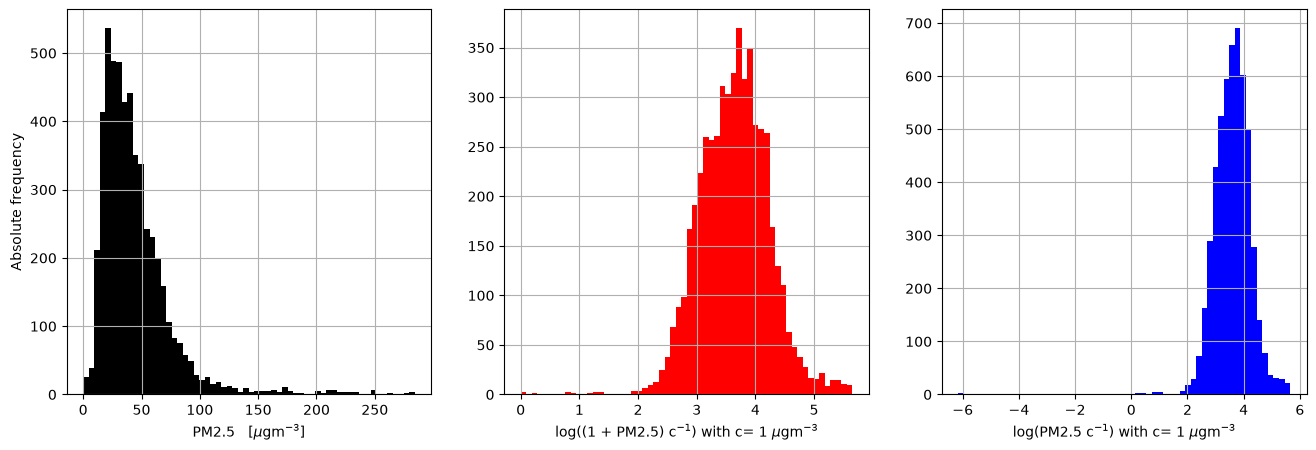

In [7]:
# Histograms of PM2.5 and its log
fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize=(16,5))
analysis_df["pm25"].hist(ax=ax1, color="black",bins=60)
analysis_df["log1p_pm25"].hist(ax=ax2, color="red", bins=60)
analysis_df["log_pm25"].hist(ax=ax3, color="blue", bins=60)
ax1.set_ylabel("Absolute frequency")
ax1.set_xlabel(r"PM2.5   [$\mu$gm$^{-3}$]")
ax2.set_xlabel(r"log((1 + PM2.5) c$^{-1}$) with c= 1 $\mu$gm$^{-3}$")
ax3.set_xlabel(r"log(PM2.5 c$^{-1}$) with c= 1 $\mu$gm$^{-3}$");

For now I will keep $\log(1+x)$, because for the moment it's easier than dealing with the very low valued reading outliers.
They may be genuine readings but could just be measurement floor artifacts where PM2.5 < MDL.

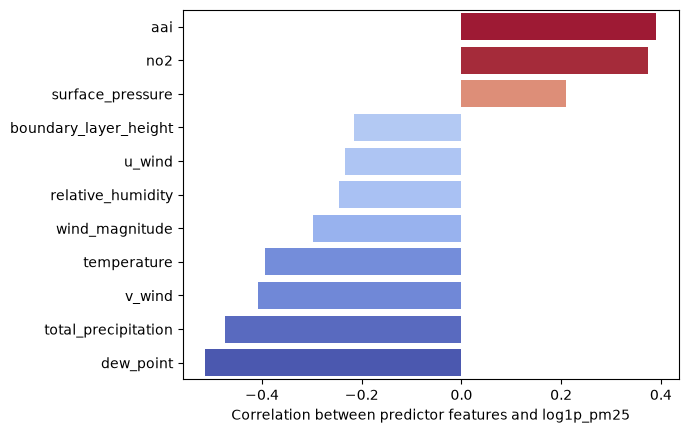

In [8]:
# Correlation between the target and the predictors
log1p_pm25_corr = (analysis_df[columns_to_check + ["log1p_pm25"]]
             .corr(numeric_only=True)["log1p_pm25"]
             .sort_values(ascending=False)
             .drop(["pm25", "log1p_pm25"])
            )
ax = sns.barplot(x=log1p_pm25_corr.values, y=log1p_pm25_corr.index, hue=log1p_pm25_corr.values, legend=False, palette="coolwarm")
ax.set_xlabel("Correlation between predictor features and log1p_pm25")
ax.set_ylabel("");                                                                                            

<Axes: >

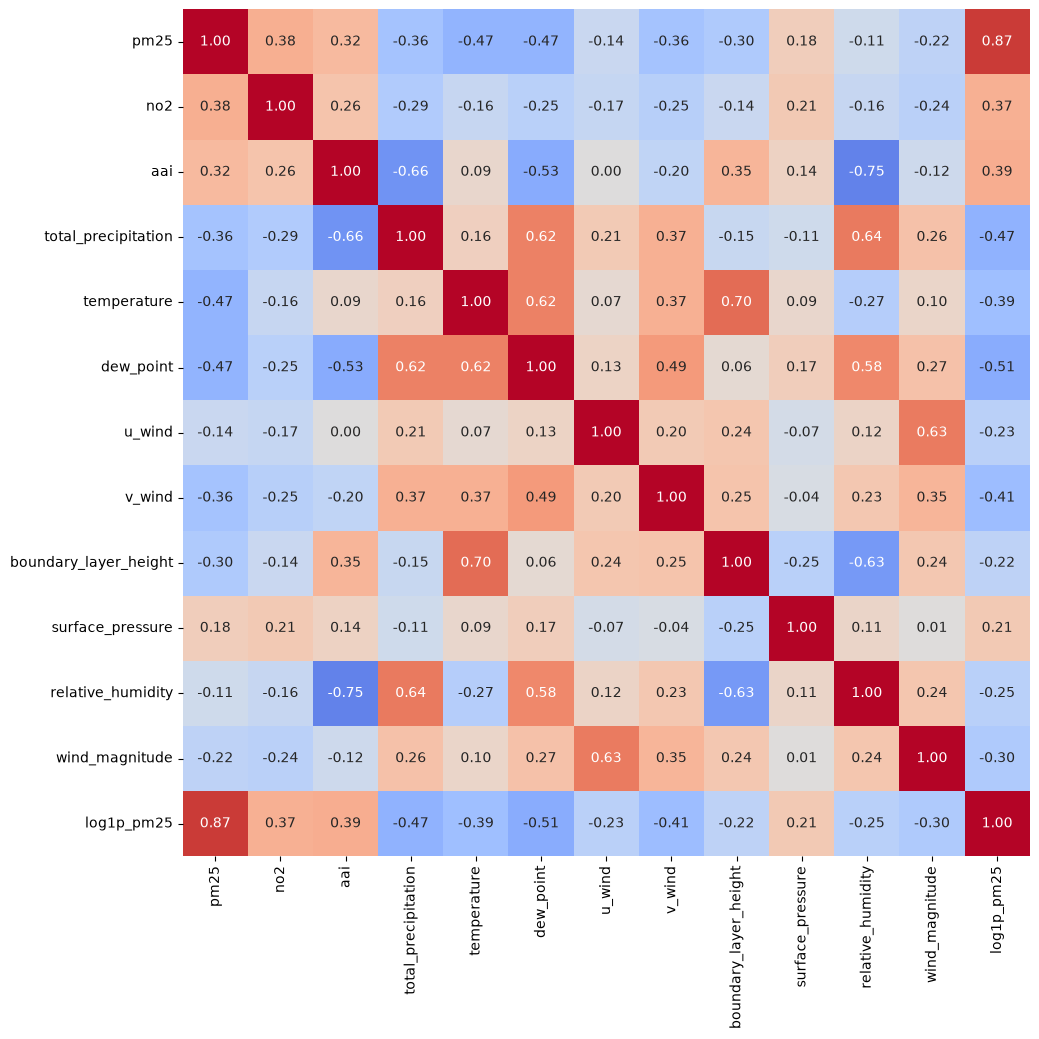

In [9]:
# Correlation between all features and target
fig, ax = plt.subplots(figsize=(11,11))
corr = analysis_df[columns_to_check + ["log1p_pm25"]].corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar=False, ax=ax)

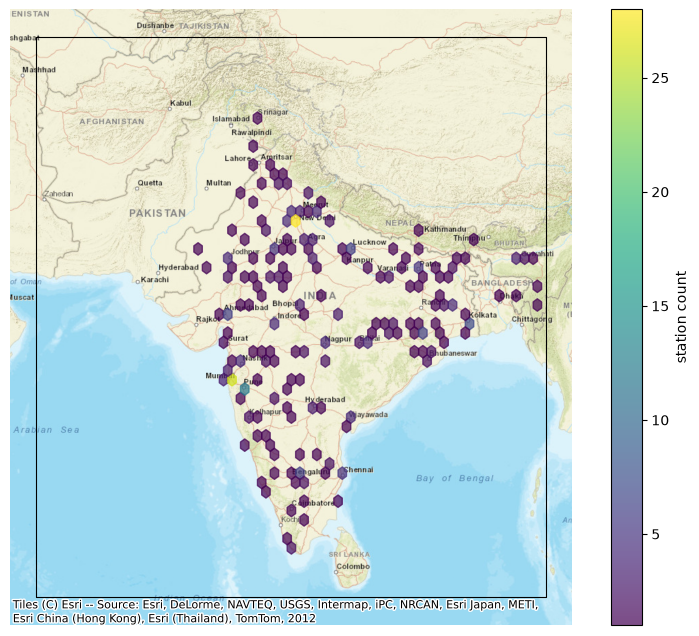

In [10]:
# Where are the stations concentrated?
from shapely.geometry import box

unique_stations = analysis_df[["station_id", "longitude", "latitude"]].drop_duplicates("station_id")
stations_gdf = gpd.GeoDataFrame(
    unique_stations,
    geometry=gpd.points_from_xy(unique_stations.longitude, unique_stations.latitude),
    crs="EPSG:4326",
).to_crs(epsg=3857)  # contextily basemaps are served in Web Mercator

region_outline = gpd.GeoDataFrame(geometry=[box(*BOUNDING_BOX)], crs="EPSG:4326").to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10, 8))
region_outline.boundary.plot(ax=ax, color="black", linewidth=0.8)

hb = ax.hexbin(stations_gdf.geometry.x, stations_gdf.geometry.y, gridsize=40, cmap="viridis", mincnt=1, alpha=0.7)
fig.colorbar(hb, ax=ax, label="station count")
# CartoDB Positron and plain OpenStreetMap tiles both refused these requests (API key
# required / usage-policy block, respectively) -- Esri's tiles serve without either issue
cx.add_basemap(ax, crs=stations_gdf.crs, source=cx.providers.Esri.WorldStreetMap)
ax.set_aspect("equal")
ax.set_axis_off()

## Step 4 - Extra feature engineering
Add a month of year category

In [11]:
# Tree based models handle categorical features better then one-hot encoded categories
analysis_df["month_of_year"] = pd.Categorical(analysis_df["month"].dt.month, categories=range(1, 13))

## Step 5 - Save and record metadata

In [12]:
# Notebook metadata
metadata = {
    "columns_checked_for_nan": columns_to_check,
    "n_dropped_rows": n_dropped_data,
    "dropped_rows_by_column": nan_counts.to_dict(),
    "target_transform": "log1p",
    "target_transform_note": "log(x) also computed for comparison; log1p kept for now to avoid "
                              "dealing with a handful of very low PM2.5 readings that may be "
                              "measurement-floor artifacts",
    "log1p_pm25_correlations": log1p_pm25_corr.round(3).to_dict(),
    "n_stations": int(analysis_df["station_id"].nunique()),
    "n_months": int(analysis_df["month"].nunique()),
    "n_data_points": len(analysis_df),
}

with open("../configs/eda_metadata.yaml", "w") as f:
    yaml.safe_dump(metadata, f, sort_keys=False)

analysis_df.to_parquet(PROCESSED_DATA_DIR / "master_station_df.parquet")